<a href="https://colab.research.google.com/github/Prajwaln08/SQLSmith/blob/main/notebooks/12_Schema_Linking_and_SQL_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SQLSmith — Notebook 12 | Schema Linking & Read-only SQL Validation

**Milestone C · CPU only · Spider 1.0 development set · 1,034 questions / 20 databases**

**Purpose:** Test (i) deterministic *table ranking* for schema linking, and (ii) a conservative *read-only SQL compilation gate* against all four **frozen** prediction sets. Produce exact error/coverage statistics and a prioritized review queue; do **not** claim an accuracy improvement because no SQL is regenerated or repaired.

**Prerequisite:** Notebook 11 completed and its four official per-question correctness labels reconciled to Notebook 10. This notebook **does not rerun inference or official evaluation**.

**Methodological warning:** Spider dev was used to select previous models. Every result here is **exploratory**. Gold SQL is used only **after** the question-only ranker is frozen, for evaluation. Never use gold SQL or correctness labels as ranker inputs. A separate unseen database benchmark is required before production claims.

## 1 — Install CPU-only dependencies

This run needs no CUDA, Transformers, or model weights.

In [1]:
%pip install -q "pandas>=2.1" "numpy>=1.26" "matplotlib>=3.8" "sqlglot>=25,<30" "huggingface_hub>=0.25"

## 2 — Google Drive, inputs, and frozen experiment configuration

Run once. This verifies Notebook 11's 1,034 aligned rows and the four saved per-question decisions. Do not silently substitute a different evaluation file.

In [2]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from IPython.display import display
import pandas as pd, numpy as np
import json, hashlib, re, sqlite3, zipfile, time, math

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/Prajwal/Projects/SQLSmith')
PRIOR = PROJECT/'results/milestone_C/error_analysis'
OUT = PROJECT/'results/milestone_C/schema_validation'
OUT.mkdir(parents=True,exist_ok=True)
QUESTIONS_PATH=PRIOR/'11_all_questions_paired.csv'
MANIFEST11=PRIOR/'11_error_analysis_manifest.json'
RECON11=PRIOR/'11_score_reconciliation.csv'
for p in (QUESTIONS_PATH, MANIFEST11, RECON11):
    assert p.is_file(),f'Notebook 11 prerequisite missing: {p}'

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):
            h.update(block)
    return h.hexdigest()

Q=pd.read_csv(QUESTIONS_PATH,keep_default_na=False)
Q['index']=pd.to_numeric(Q['index']).astype(int)
Q=Q.sort_values('index').reset_index(drop=True)
assert len(Q)==1034 and Q['index'].tolist()==list(range(1,1035))
assert Q.db_id.nunique()==20
PAIRS=[('1.5b','base'),('1.5b','sft'),('7b','base'),('7b','sft')]
for m,v in PAIRS:
    for col in (f'{m}_{v}_correct',f'{m}_{v}_sql'):
        assert col in Q.columns,f'Missing paired data: {col}'
    Q[f'{m}_{v}_correct']=pd.to_numeric(Q[f'{m}_{v}_correct']).astype(int)
    assert set(Q[f'{m}_{v}_correct'].unique())<=set([0,1])
EXPECTED_COUNTS={('1.5b','base'):439,('1.5b','sft'):614,
                 ('7b','base'):757,('7b','sft'):777}
# The expected counts are derived from Notebook 11's reconciled 1,034 outcomes;
# verify against its actual signed-off reconciliation rather than a rounded score alone.
recon=pd.read_csv(RECON11)
for m,v in PAIRS:
    rows=recon[(recon.model==m)&(recon.variant==v)]
    assert len(rows)==1
    observed=int(Q[f'{m}_{v}_correct'].sum())
    assert observed==int(rows.iloc[0]['correct']),f'Label mismatch: {m}/{v}'
    print(f'{m:4} {v:4}: {observed}/1034 official correct labels verified')
source_meta=json.loads(MANIFEST11.read_text(encoding='utf-8'))
assert source_meta['official_test_suite_commit']=='e97acc546ecbee8fa27fa8dbf025ef61493a876c'
print('Input SHA256:',sha256_file(QUESTIONS_PATH))
print('Output folder:', OUT)

Mounted at /content/drive
1.5b base: 439/1034 official correct labels verified
1.5b sft : 614/1034 official correct labels verified
7b   base: 757/1034 official correct labels verified
7b   sft : 777/1034 official correct labels verified
Input SHA256: acee7f3e272447f95f09a452e55eaa1ade2ce2a631782a87f14712d12ab9aa05
Output folder: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_C/schema_validation


## 3 — Recover the pinned original Spider schema and database files

The source archive is the same SHA-256-pinned package used in Notebooks 06, 10 and 11. SQLite is opened **read-only** later; the benchmark databases are never modified.

In [3]:
from huggingface_hub import hf_hub_download
SPIDER=Path('/content/sqlsmith_data/spider_data')
ARCHIVE=hf_hub_download(repo_id='HAL-9001/spider-databases',repo_type='dataset',filename='spider_data.zip')
assert sha256_file(ARCHIVE)=='00636695dabed6b5f4b8328a16b13e069a2f16591d5efcce57660669c85b121b','Unexpected Spider archive'
if not all((SPIDER/p).is_file() for p in ('tables.json','dev.json')):
    dest=Path('/content/sqlsmith_data');dest.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(ARCHIVE) as z:
        for info in z.infolist():
            assert (dest/info.filename).resolve().is_relative_to(dest.resolve()),'Unsafe ZIP member'
        z.extractall(dest)
TABLES=SPIDER/'tables.json'; DEV=SPIDER/'dev.json'
assert sha256_file(DEV)==source_meta['spider_dev_sha256'],'Spider dev changed'
raw_dev=json.loads(DEV.read_text(encoding='utf-8'))
schemas={row['db_id']:row for row in json.loads(TABLES.read_text(encoding='utf-8'))}
assert len(raw_dev)==len(Q)
for i,row in Q.iterrows():
    assert row.db_id==raw_dev[i]['db_id'] and row.question==raw_dev[i]['question']
    assert ' '.join(str(row.gold_sql).split())==' '.join(raw_dev[i]['query'].split())
for db in Q.db_id.unique():
    assert db in schemas
    assert (SPIDER/'database'/db/(db+'.sqlite')).is_file(),f'Missing SQLite database: {db}'
print('PASS: 20 database schemas, original SQLite files, and question labels aligned')

spider_data.zip: reconstructing file:   0%|          |  0.00B /  206MB            

spider_data.zip: downloading bytes:           |  0.00B            

PASS: 20 database schemas, original SQLite files, and question labels aligned


## 4 — Freeze a question-only, deterministic schema ranker

**No model calls.** This lightweight baseline scores original table/column names using token overlap with the question; FK-adjacent tables receive only a small tie-break boost. We use *no gold SQL and no official correctness labels* when ranking.

This is deliberately simple. A higher-ranked table list can later be injected into a prompt, but **this notebook does not alter existing predictions**.

In [4]:
import sqlglot
from sqlglot import exp

STOP={'a','an','the','of','to','for','in','on','with','is','are','was','were','and','or',
      'by','from','each','all','show','list','find','give','what','which','who','how',
      'many','much','number','total','name','names','id','ids','that','have','has',
      'than','at','as','be','do','does','did','their','its','me','please','there'}
def tokens(s):
    # Split underscore/camel case, lowercase, stable tokens; no corpus-specific synonyms.
    s=re.sub(r'([a-z])([A-Z])',r'\1 \2',str(s))
    return [t for t in re.findall(r'[a-z0-9]+',s.lower().replace('_',' ')) if t not in STOP]

def table_descriptors(sch):
    names=sch['table_names_original']; names_norm=sch['table_names']
    cols=sch['column_names_original']
    desc=[]
    for tid,table in enumerate(names):
        column_names=[c for table_id,c in cols if table_id==tid]
        table_terms=set(tokens(table))|set(tokens(names_norm[tid]))
        col_terms=set(t for name in column_names for t in tokens(name))
        desc.append({'table':table,'table_id':tid,'table_terms':table_terms,
                     'column_terms':col_terms,'columns':column_names})
    return desc

def rank_tables(question,sch):
    q=set(tokens(question)); descriptors=table_descriptors(sch)
    # FK-based centrality is a tiny tie breaker, not an oracle join path.
    deg=Counter()
    for a,b in sch.get('foreign_keys',[]):
        a_table=sch['column_names_original'][a][0]
        b_table=sch['column_names_original'][b][0]
        if a_table>=0:deg[a_table]+=1
        if b_table>=0:deg[b_table]+=1
    scores=[]
    for d in descriptors:
        t=len(q & d['table_terms']); c=len(q & d['column_terms'])
        full=2 if d['table_terms'] and d['table_terms'].issubset(q) else 0
        score=5*t+1.25*c+full+.01*min(deg[d['table_id']],10)
        scores.append((d['table'],float(score)))
    return [table for table,_ in sorted(scores,key=lambda v:(-v[1],v[0].lower()))],scores

# Leakage guard: rank_tables accepts only (question, schema) and cannot see gold SQL.
example=Q.iloc[0]
print('Example question:',example.question)
print('Ranked tables:',rank_tables(example.question,schemas[example.db_id])[0][:5])
print('Schema linker frozen: token match + FK tie-break; K ∈ {1,3,5}')

Example question: How many singers do we have?
Ranked tables: ['concert', 'singer_in_concert', 'singer', 'stadium']
Schema linker frozen: token match + FK tie-break; K ∈ {1,3,5}


## 5 — Measure gold-table recall at top-1 / top-3 / top-5

Gold SQL is consulted **only here, after predictions are generated**, to estimate how often the ranker retains all needed tables. It is not a training signal or a prompt feature. SQLGlot parse failures, correlated aliases, and inconsistent naming are reported as unevaluable rather than silently scored correct.

In [5]:
def gold_tables(sql,sch):
    try:
        tree=sqlglot.parse_one(str(sql),read='sqlite')
        if tree is None:return None,'parse_failure'
        actual={t.lower():t for t in sch['table_names_original']}
        found=set()
        # CTE names are not physical tables.
        cte_names={x.alias_or_name.lower() for x in tree.find_all(exp.CTE) if x.alias_or_name}
        for t in tree.find_all(exp.Table):
            name=str(t.name).lower()
            if name in cte_names:continue
            if name not in actual:return None,'unknown_gold_table:'+name
            found.add(actual[name])
        return found,'ok'
    except Exception as exc:return None,'parse_failure:'+type(exc).__name__

link_records=[]
for _,r in Q.iterrows():
    sch=schemas[r.db_id]
    ranked,_=rank_tables(r.question,sch)
    required,status=gold_tables(r.gold_sql,sch)
    rec={'index':int(r['index']),'db_id':r.db_id,'difficulty':r.difficulty,
         'question':r.question,'gold_parse_status':status,
         'n_tables':len(ranked),'gold_table_count':len(required) if required is not None else None,
         'gold_tables':json.dumps(sorted(required)) if required is not None else '',
         'ranking':json.dumps(ranked),'top_1':json.dumps(ranked[:1]),
         'top_3':json.dumps(ranked[:3]),'top_5':json.dumps(ranked[:5])}
    for k in [1,3,5]:
        selection=set(ranked[:k]);
        rec[f'gold_all_recalled_at_{k}']=(required.issubset(selection) if required is not None else None)
        rec[f'gold_fraction_recalled_at_{k}']=(len(required&selection)/len(required) if required else (1.0 if required==set() else None))
    link_records.append(rec)
LINK=pd.DataFrame(link_records)
LINK.to_csv(OUT/'12_schema_linking_per_question.csv',index=False)
valid=LINK[LINK.gold_parse_status=='ok']
link_summary=pd.DataFrame([{'top_k':k,'evaluable_questions':len(valid),
                            'all_gold_tables_recalled':int(valid[f'gold_all_recalled_at_{k}'].sum()),
                            'all_table_recall_rate':float(valid[f'gold_all_recalled_at_{k}'].mean()),
                            'mean_table_recall':float(valid[f'gold_fraction_recalled_at_{k}'].mean()),
                            'avg_selected_tables':float(valid[f'top_{k}'].map(lambda x:len(json.loads(x))).mean())}
                           for k in [1,3,5]])
link_summary.to_csv(OUT/'12_schema_linking_topk.csv',index=False)
display(link_summary)
print('Gold parsing status:',LINK.gold_parse_status.value_counts().to_dict())

,top_k,evaluable_questions,all_gold_tables_recalled,all_table_recall_rate,mean_table_recall,avg_selected_tables
0,1,1034,473,0.457447,0.643456,1.000000
1,3,1034,978,0.945841,0.971228,2.932302
2,5,1034,1028,0.994197,0.996454,3.743714


Gold parsing status: {'ok': 1034}


## 6 — Build a conservative, read-only SQL validator

Three separate outcomes are recorded:

- **Policy syntax gate:** exactly one SELECT/query-expression statement, no write/admin commands or multiple statements.
- **SQLite compile diagnostic:** `EXPLAIN QUERY PLAN` against a **read-only connection**, with SQLite authorizer permitting only reads / select / functions, and progress-limited execution. This detects many missing columns/tables and syntax errors; compilation alone does **not** establish semantic correctness.
- **Official correctness:** imported *unchanged* from Notebook 11; never inferred from compilation.

**Threat model:** This is an exploratory offline check against **public Spider databases only**, not a sandbox for hostile SQL. Production requires a separate query-service process, least-privilege credentials, resource limits, and dialect-specific hardening.

In [6]:
ALLOWED_ROOTS=(exp.Select, exp.Union, exp.Intersect, exp.Except)
# sqlglot may parse SQLite CTE as Select; reject DML/DDL anywhere in the AST.
BLOCKED_NODE_NAMES={'Insert','Update','Delete','Create','Drop','Alter','Merge','Command',
                    'Transaction','Commit','Rollback','Grant','Revoke','Attach','Detach',
                    'Pragma','Use','Set','TruncateTable','Copy'}

def classify_sql(sql):
    raw=str(sql).strip()
    if not raw:return ('empty_sql',None)
    try:
        statements=sqlglot.parse(raw,read='sqlite',error_level='RAISE')
    except Exception:return ('parse_failure',None)
    if len(statements)!=1 or statements[0] is None:return ('multiple_or_empty_statements',None)
    tree=statements[0]
    if not isinstance(tree,ALLOWED_ROOTS):return ('non_readonly_root',None)
    if any(type(node).__name__ in BLOCKED_NODE_NAMES for node in tree.walk()):
        return ('unsafe_ast',None)
    # Avoid string matching semicolons inside literals. SQLGlot is the parser of record.
    return ('select_only',raw)

DENIED_ACTIONS=set()
for a in ('SQLITE_INSERT','SQLITE_UPDATE','SQLITE_DELETE','SQLITE_CREATE_TABLE',
          'SQLITE_DROP_TABLE','SQLITE_ALTER_TABLE','SQLITE_ATTACH','SQLITE_DETACH',
          'SQLITE_PRAGMA','SQLITE_TRANSACTION','SQLITE_CREATE_VIEW','SQLITE_DROP_VIEW',
          'SQLITE_CREATE_TRIGGER','SQLITE_DROP_TRIGGER','SQLITE_CREATE_INDEX',
          'SQLITE_DROP_INDEX','SQLITE_ANALYZE','SQLITE_REINDEX','SQLITE_CREATE_VTABLE',
          'SQLITE_DROP_VTABLE'):
    if hasattr(sqlite3,a): DENIED_ACTIONS.add(getattr(sqlite3,a))

def readonly_authorizer(action,arg1,arg2,dbname,source):
    if action in DENIED_ACTIONS:return sqlite3.SQLITE_DENY
    if action==sqlite3.SQLITE_FUNCTION:
        # Built-in function usage is allowed by SQLite; no untrusted extensions loaded.
        return sqlite3.SQLITE_OK
    return sqlite3.SQLITE_OK

def sqlite_compile(db_id,sql):
    db=SPIDER/'database'/db_id/(db_id+'.sqlite')
    if not db.is_file():return 'missing_original_db'
    conn=None
    try:
        conn=sqlite3.connect(db.resolve().as_uri()+'?mode=ro',uri=True,timeout=2)
        conn.execute('PRAGMA query_only=ON')  # set before authorizer
        conn.set_authorizer(readonly_authorizer)
        started=time.monotonic()
        conn.set_progress_handler(lambda: 1 if time.monotonic()-started>3 else 0,1000)
        conn.execute('EXPLAIN QUERY PLAN '+sql).fetchall()
        return 'compiles'
    except sqlite3.Error as e:
        msg=str(e).lower()
        for fragment,label in (
          ('no such column','unknown_column'),('no such table','unknown_table'),
          ('ambiguous column name','ambiguous_column'),('syntax error','syntax_error'),
          ('no such function','unknown_function'),('misuse of aggregate','aggregate_error'),
          ('wrong number of arguments','function_arity_error'),
          ('interrupted','compile_timeout'),('not authorized','blocked_by_authorizer')):
            if fragment in msg:return label
        return 'sqlite_other_error'
    finally:
        if conn is not None:conn.close()

# Sanity checks before scanning 4,136 frozen predictions.
for sql in ('SELECT 1','WITH x AS (SELECT 1) SELECT * FROM x'):
    kind,clean=classify_sql(sql)
    assert kind=='select_only'
assert classify_sql('DROP TABLE users')[0]!='select_only'
assert classify_sql('SELECT 1; DELETE FROM users')[0]!='select_only'
print('Read-only validator smoke checks passed')

Read-only validator smoke checks passed


## 7 — Audit all four frozen prediction sets (4,136 rows)

This is CPU-only. The validator does not execute result-producing SELECT queries; it asks SQLite to compile an EXPLAIN plan. Errors are diagnostic. Cache only the finished, signature-verified table; if interrupted, simply rerun this cell.

In [7]:
PRED_SHA=sha256_file(QUESTIONS_PATH)
CONFIG={'source_sha256':PRED_SHA,'spider_tables_sha256':sha256_file(TABLES),
        'sqlite_version':sqlite3.sqlite_version,'sqlglot_version':sqlglot.__version__,
        'validator_version':'12_v1_select_ast_sqlite_explain_readonly',
        'questions':1034,'variants':4}
CONFIG_PATH=OUT/'12_validation_config.json'
if CONFIG_PATH.exists():
    assert json.loads(CONFIG_PATH.read_text(encoding='utf-8'))==CONFIG,'Prior validator cache uses different inputs or package version; archive it before rerunning.'
else:CONFIG_PATH.write_text(json.dumps(CONFIG,indent=2),encoding='utf-8')
VALIDATION_PATH=OUT/'12_all_predictions_validation.csv'
if VALIDATION_PATH.exists():
    V=pd.read_csv(VALIDATION_PATH,keep_default_na=False)
    assert len(V)==4136 and not V.duplicated(['index','model','variant']).any()
    print('Using validated cached results:',VALIDATION_PATH)
else:
    from tqdm.auto import tqdm
    records=[]
    for _,q in tqdm(Q.iterrows(),total=len(Q),desc='SQLite readonly compilation'):
        for m,v in PAIRS:
            sql=q[f'{m}_{v}_sql']
            policy,clean=classify_sql(sql)
            status=sqlite_compile(q.db_id,clean) if policy=='select_only' else 'not_checked'
            records.append({'index':int(q['index']),'db_id':q.db_id,'model':m,'variant':v,
                            'difficulty':q.difficulty,'official_correct':int(q[f'{m}_{v}_correct']),
                            'policy_status':policy,'sqlite_status':status,
                            'accepted_by_gate':int(policy=='select_only' and status=='compiles'),
                            'predicted_sql':sql})
    V=pd.DataFrame(records)
    assert len(V)==4136 and not V.duplicated(['index','model','variant']).any()
    V.to_csv(VALIDATION_PATH,index=False)
for m,v in PAIRS:
    sub=V[(V.model==m)&(V.variant==v)]
    assert len(sub)==1034 and int(sub.official_correct.sum())==int(Q[f'{m}_{v}_correct'].sum())
print('PASS: 4,136 schema validation diagnostics; official decisions unchanged')
display(V.groupby(['model','variant','policy_status']).size().reset_index(name='n'))

SQLite readonly compilation:   0%|          | 0/1034 [00:00<?, ?it/s]

PASS: 4,136 schema validation diagnostics; official decisions unchanged


,model,variant,policy_status,n
0,1.5b,base,parse_failure,1
1,1.5b,base,select_only,1033
2,1.5b,sft,select_only,1034
3,7b,base,select_only,1034
4,7b,sft,select_only,1034


## 8 — Quantify gate detection, rejection risk, and failure mix

A *gate* can **reject** an invalid query, but it cannot automatically make that SQL correct. Report:

- **Gate rejection rate** and **official-wrong captured** (diagnostic recall of failures).
- **Official-correct rejected** (false rejection: serious regression risk).
- **Official-wrong passed** (semantically wrong SQL that compilation cannot identify).

Do **not** report accuracy improvement based on refusing to answer.

In [8]:
metrics=[]
for (m,v),g in V.groupby(['model','variant']):
    wrong=g.official_correct==0;reject=g.accepted_by_gate==0
    metrics.append({'model':m,'variant':v,'n':len(g),'official_accuracy':float(g.official_correct.mean()),
      'compile_pass_rate':float((~reject).mean()),'rejected_total':int(reject.sum()),
      'official_wrong_total':int(wrong.sum()),'wrong_rejected':int((wrong&reject).sum()),
      'wrong_passed':int((wrong&~reject).sum()),
      'correct_rejected':int((~wrong&reject).sum()),
      'wrong_capture_rate':float((wrong&reject).sum()/wrong.sum()) if wrong.any() else None,
      'precision_of_rejection_for_wrong':float((wrong&reject).sum()/reject.sum()) if reject.any() else None})
METRICS=pd.DataFrame(metrics).sort_values(['model','variant'])
assert (METRICS.correct_rejected>=0).all()
METRICS.to_csv(OUT/'12_validation_detection_metrics.csv',index=False)
display(METRICS)
STATUS=(V.groupby(['model','variant','policy_status','sqlite_status'])
           .agg(n=('index','size'),wrong=('official_correct',lambda x:int((x==0).sum())))
           .reset_index().sort_values(['model','variant','n'],ascending=[True,True,False]))
STATUS.to_csv(OUT/'12_compilation_error_breakdown.csv',index=False)
display(STATUS.groupby(['model','variant']).head(10))

,model,variant,n,official_accuracy,compile_pass_rate,rejected_total,official_wrong_total,wrong_rejected,wrong_passed,correct_rejected,wrong_capture_rate,precision_of_rejection_for_wrong
0,1.5b,base,1034,0.424565,0.697292,313,595,313,282,0,0.526050,1.0
1,1.5b,sft,1034,0.593810,0.843327,162,420,162,258,0,0.385714,1.0
2,7b,base,1034,0.732108,0.969052,32,277,32,245,0,0.115523,1.0
3,7b,sft,1034,0.751451,0.955513,46,257,46,211,0,0.178988,1.0


,model,variant,policy_status,sqlite_status,n,wrong
2,1.5b,base,select_only,compiles,721,282
3,1.5b,base,select_only,unknown_column,284,284
5,1.5b,base,select_only,unknown_table,15,15
1,1.5b,base,select_only,aggregate_error,12,12
0,1.5b,base,parse_failure,not_checked,1,1
4,1.5b,base,select_only,unknown_function,1,1
8,1.5b,sft,select_only,compiles,872,258
10,1.5b,sft,select_only,unknown_column,141,141
11,1.5b,sft,select_only,unknown_table,17,17
9,1.5b,sft,select_only,sqlite_other_error,2,2


## 9 — Which problems are likely schema-grounding errors?

We separately group unknown columns/tables and ambiguous column references. These are *observable SQLite failures*, not guaranteed root causes. Even if a SQL query compiles, it can reference the wrong column or table and remain semantically incorrect.

In [9]:
SCHEMA_ERRORS={'unknown_column','unknown_table','ambiguous_column'}
V['schema_compile_issue']=V.sqlite_status.isin(SCHEMA_ERRORS)
summary_schema=(V.groupby(['model','variant'])
    .agg(schema_compile_issues=('schema_compile_issue','sum'),
         official_wrong=('official_correct',lambda x:int((x==0).sum())),
         n=('index','size')).reset_index())
summary_schema['schema_issue_pct_all']=100*summary_schema.schema_compile_issues/summary_schema.n
summary_schema.to_csv(OUT/'12_schema_grounding_diagnostics.csv',index=False)
display(summary_schema)
# Only cases with observable schema failures go into this review list.
review=V[V.schema_compile_issue].copy()
review['priority']=np.where(review.official_correct==0,0,1)
review=review.sort_values(['priority','model','variant','db_id','index'])
review=review.merge(Q[['index','question','gold_sql']],on='index',how='left',validate='many_to_one')
review.to_csv(OUT/'12_schema_grounding_review_queue.csv',index=False)
print('Candidate schema-grounding review cases:',len(review))
display(review[['model','variant','index','db_id','sqlite_status','official_correct','question']].head(20))

,model,variant,schema_compile_issues,official_wrong,n,schema_issue_pct_all
0,1.5b,base,299,595,1034,28.916828
1,1.5b,sft,159,420,1034,15.377176
2,7b,base,31,277,1034,2.998066
3,7b,sft,46,257,1034,4.448743


Candidate schema-grounding review cases: 535


,model,variant,index,db_id,sqlite_status,official_correct,question
0,1.5b,base,497,battle_death,unknown_column,0,What are the death and injury situations cause...
1,1.5b,base,501,battle_death,unknown_column,0,What is the ship id and name that caused most ...
2,1.5b,base,507,battle_death,unknown_column,0,What are the notes of the death events which h...
3,1.5b,base,96,car_1,unknown_column,0,Which model of the car has the minimum horsepo...
4,1.5b,base,97,car_1,unknown_column,0,What is the model of the car with the smallest...
5,1.5b,base,98,car_1,unknown_column,0,Find the model of the car whose weight is belo...
6,1.5b,base,99,car_1,unknown_column,0,What is the model for the car with a weight sm...
7,1.5b,base,100,car_1,unknown_column,0,Find the name of the makers that produced some...
8,1.5b,base,101,car_1,unknown_column,0,What is the name of the different car makers w...
9,1.5b,base,102,car_1,unknown_column,0,Find the make and production time of the cars ...


## 10 — Ranker misses and schema size / difficulty breakdown

Measure where top-K pruning omits gold tables; this is a **risk analysis** for *future* prompt pruning. The ranking is not inserted into the existing model prompt, so inference accuracy is unchanged.

In [10]:
LINK_DETAIL=LINK.merge(Q[['index','question','difficulty']],on=['index','question','difficulty'],validate='one_to_one')
miss=LINK_DETAIL[(LINK_DETAIL.gold_parse_status=='ok')&(LINK_DETAIL.gold_all_recalled_at_3==False)].copy()
miss=miss.sort_values(['n_tables','db_id','index'],ascending=[False,True,True])
miss.to_csv(OUT/'12_schema_linking_top3_misses.csv',index=False)
by_diff=[]
for difficulty,g in valid.groupby('difficulty'):
    by_diff.append({'difficulty':difficulty,'n':len(g),
       'top1_all_gold_recalled':float(g.gold_all_recalled_at_1.mean()),
       'top3_all_gold_recalled':float(g.gold_all_recalled_at_3.mean()),
       'top5_all_gold_recalled':float(g.gold_all_recalled_at_5.mean())})
DIFFICULTY=pd.DataFrame(by_diff).sort_values('difficulty')
DIFFICULTY.to_csv(OUT/'12_schema_linking_by_difficulty.csv',index=False)
display(DIFFICULTY)
print('Top-3 gold-table coverage misses:',len(miss))
display(miss[['index','db_id','difficulty','gold_tables','top_3','question']].head(12))

,difficulty,n,top1_all_gold_recalled,top3_all_gold_recalled,top5_all_gold_recalled
0,easy,248,0.786290,0.979839,0.991935
1,extra,166,0.048193,0.837349,0.975904
2,hard,174,0.316092,0.902299,1.000000
3,medium,446,0.482063,0.984305,1.000000


Top-3 gold-table coverage misses: 56


,index,db_id,difficulty,gold_tables,top_3,question
518,519,student_transcripts_tracking,easy,"[""Degree_Programs""]","[""Departments"", ""Student_Enrolment"", ""Student_...",How many different departments offer degrees?
520,521,student_transcripts_tracking,easy,"[""Degree_Programs""]","[""Student_Enrolment"", ""Student_Enrolment_Cours...",How many different degrees are offered?
526,527,student_transcripts_tracking,medium,"[""Courses"", ""Sections""]","[""Sections"", ""Student_Enrolment_Courses"", ""Add...",What are the names and ids of every course wit...
529,530,student_transcripts_tracking,extra,"[""Semesters"", ""Student_Enrolment""]","[""Student_Enrolment"", ""Student_Enrolment_Cours...",What is the semester which most student regist...
549,550,student_transcripts_tracking,extra,"[""Addresses"", ""Student_Enrolment"", ""Students""]","[""Students"", ""Degree_Programs"", ""Student_Enrol...",Find the last name of the students who current...
550,551,student_transcripts_tracking,extra,"[""Addresses"", ""Student_Enrolment"", ""Students""]","[""Degree_Programs"", ""Students"", ""Student_Enrol...",What are the last name of the students who liv...
552,553,student_transcripts_tracking,medium,"[""Transcript_Contents"", ""Transcripts""]","[""Courses"", ""Transcript_Contents"", ""Student_En...",What is the date and id of the transcript with...
571,572,student_transcripts_tracking,hard,"[""Transcript_Contents""]","[""Transcripts"", ""Student_Enrolment_Courses"", ""...",How many times at most can a course enrollment...
572,573,student_transcripts_tracking,hard,"[""Transcript_Contents""]","[""Transcripts"", ""Student_Enrolment_Courses"", ""...",What is the maximum number of times that a cou...
575,576,student_transcripts_tracking,extra,"[""Degree_Programs"", ""Student_Enrolment""]","[""Students"", ""Student_Enrolment"", ""Semesters""]",Find the semester when both Master students an...


## 11 — Define a **shadow-only** policy and compare model variants

A shadow gate logs likely failures without blocking production queries. We show both the number of *correct queries flagged* and *wrong queries flagged*, including the regression cases from Notebook 11. This prevents confusing a rejection mechanism with a repair mechanism.

In [11]:
shadow=[]
for m in ('1.5b','7b'):
    b=V[(V.model==m)&(V.variant=='base')].set_index('index')
    s=V[(V.model==m)&(V.variant=='sft')].set_index('index')
    assert b.index.equals(s.index)
    change=Q.set_index('index')[f'{m}_change']
    for idx in s.index:
        r=s.loc[idx]; old=b.loc[idx]
        shadow.append({'model':m,'index':int(idx),'db_id':r.db_id,
                       'sft_official_correct':int(r.official_correct),
                       'base_official_correct':int(old.official_correct),
                       'sft_flagged':int(not bool(r.accepted_by_gate)),
                       'base_flagged':int(not bool(old.accepted_by_gate)),
                       'change':str(change.loc[idx]),'sqlite_status':r.sqlite_status})
SHADOW=pd.DataFrame(shadow)
assert len(SHADOW)==2068
SHADOW.to_csv(OUT/'12_shadow_policy_paired.csv',index=False)
shadow_summary=(SHADOW.groupby(['model','change'])
  .agg(n=('index','size'),sft_flagged=('sft_flagged','sum'),base_flagged=('base_flagged','sum'))
  .reset_index())
shadow_summary.to_csv(OUT/'12_shadow_policy_summary.csv',index=False)
display(shadow_summary)

,model,change,n,sft_flagged,base_flagged
0,1.5b,correct_both,377,0,0
1,1.5b,fixed_by_sft,237,0,136
2,1.5b,regressed_after_sft,62,22,0
3,1.5b,wrong_both,358,140,177
4,7b,correct_both,694,0,0
5,7b,fixed_by_sft,83,0,12
6,7b,regressed_after_sft,63,25,0
7,7b,wrong_both,194,21,20


## 12 — Create figures and a source-backed Markdown report

Plots are saved as PNGs for GitHub documentation. Counts/denominators come from stored CSVs, not hand-entered benchmark claims.

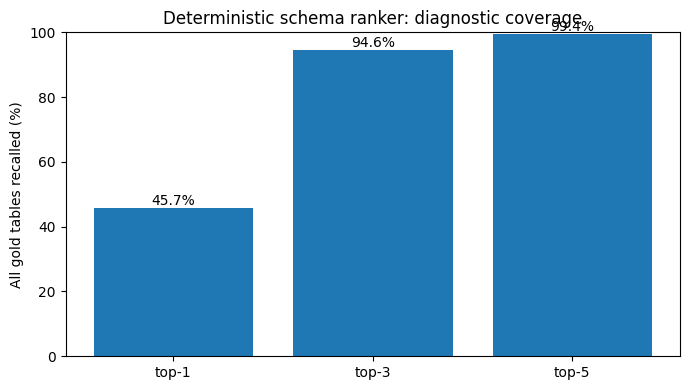

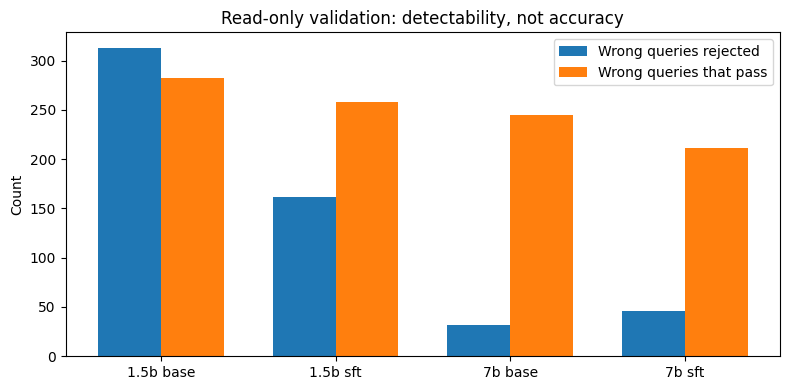

Report: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_C/schema_validation/12_schema_validation_research.md


In [12]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,4))
ax.bar([f'top-{k}' for k in link_summary.top_k],link_summary.all_table_recall_rate*100)
ax.set_ylim(0,100);ax.set_ylabel('All gold tables recalled (%)');ax.set_title('Deterministic schema ranker: diagnostic coverage')
for i,val in enumerate(link_summary.all_table_recall_rate*100): ax.text(i,val+1,f'{val:.1f}%',ha='center')
fig.tight_layout();fig.savefig(OUT/'12_schema_linking_topk.png',dpi=160);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4))
labels=[f'{r.model} {r.variant}' for r in METRICS.itertuples()]
x=np.arange(len(labels));width=.36
ax.bar(x-width/2,METRICS.wrong_rejected,width,label='Wrong queries rejected')
ax.bar(x+width/2,METRICS.wrong_passed,width,label='Wrong queries that pass')
ax.set_xticks(x,labels);ax.set_ylabel('Count');ax.set_title('Read-only validation: detectability, not accuracy');ax.legend()
fig.tight_layout();fig.savefig(OUT/'12_validation_detection.png',dpi=160);plt.show();plt.close(fig)

report=['# SQLSmith — Milestone C | Notebook 12: Schema Linking and SQL Validation','',
 '**Evaluation:** 1,034 Spider dev questions across 20 databases; 4 frozen model variants, 4,136 predictions.',
 '**Label source:** Notebook 11 official per-question evaluator decisions (unchanged).','',
 '## Table-ranking quality (gold SQL is used only for scoring)', '',
 '| Top K | Evaluable questions | All gold tables recalled | Mean table recall |','|---|---:|---:|---:|']
for r in link_summary.itertuples():
    report.append(f'| {r.top_k} | {r.evaluable_questions} | {r.all_table_recall_rate:.1%} | {r.mean_table_recall:.1%} |')
report+=['','## Read-only validator detection (no SQL correction)', '',
 '| Model | Variant | Official accuracy | Wrong rejected | Wrong passed | Correct rejected |',
 '|---|---|---:|---:|---:|---:|']
for r in METRICS.itertuples():
    report.append(f'| {r.model} | {r.variant} | {r.official_accuracy:.1%} | {r.wrong_rejected} | {r.wrong_passed} | {r.correct_rejected} |')
report+=['','## Schema-grounding diagnostics','','| Model | Variant | Unknown/ambiguous schema failures |',
 '|---|---|---:|']
for r in summary_schema.itertuples():report.append(f'| {r.model} | {r.variant} | {r.schema_compile_issues} |')
report+=['','## Interpretation and recommendations','',
 '- The ranking is deterministic and question-only; its top-K coverage is a diagnostic, **not measured downstream execution accuracy**.',
 '- SQLite EXPLAIN compilation detects certain malformed queries, not semantic mismatch. A validator cannot improve result accuracy until paired with a measured repair or regeneration policy.',
 '- `correct_rejected` measures risks of introducing a strict gate; inspect these cases before deploying a blocking policy.',
 '- Compare failure types by difficulty and database, then design a **fixed-budget** repair experiment on a separate development partition or fresh benchmark.',
 '- Any prompt pruning or repair mechanism must include a no-change control and report accuracy, regressions, latency, and abstention rate.',
 '', '## Limitations','',
 '- Public SQLite Spider data only; no clinical or private databases. This is not an enterprise SQL security boundary.',
 '- Reused Spider dev benchmark; exploratory analysis. Avoid post-hoc claims of independent generalization.',
 '- The linker ranks tables (not columns or FK join paths) and the string tokenization is intentionally simplistic.',
 '- The SQLGlot parser and SQLite EXPLAIN may disagree; dialect-specific validation is required in production.',
 '- No model weights, prompts, predictions, or official evaluator labels were changed.',
 '', '## Outputs','','`'+str(OUT)+'`','']
MEMO=OUT/'12_schema_validation_research.md'
MEMO.write_text('\n'.join(report),encoding='utf-8')
print('Report:',MEMO)

## 13 — Provenance manifest, integrity checks, and next milestone

**Do not call this an accuracy improvement:** this notebook measured detection/coverage only. In Notebook 13 we'll test a safe SQL-validation-and-repair pipeline with a held-out tuning protocol; possible next steps depend on these diagnostics.

In [13]:
files=['12_schema_linking_per_question.csv','12_schema_linking_topk.csv',
       '12_all_predictions_validation.csv','12_validation_detection_metrics.csv',
       '12_compilation_error_breakdown.csv','12_schema_grounding_diagnostics.csv',
       '12_schema_grounding_review_queue.csv','12_schema_linking_top3_misses.csv',
       '12_schema_linking_by_difficulty.csv','12_shadow_policy_paired.csv',
       '12_shadow_policy_summary.csv','12_schema_linking_topk.png',
       '12_validation_detection.png','12_schema_validation_research.md']
assert all((OUT/f).is_file() for f in files)
assert len(Q)==1034 and len(LINK)==1034 and len(V)==4136 and len(SHADOW)==2068
assert sum(V.official_correct)==sum(int(Q[f'{m}_{v}_correct'].sum()) for m,v in PAIRS)
manifest={'project':'SQLSmith','notebook':'12_Schema_Linking_and_SQL_Validation',
          'date_utc':datetime.now(timezone.utc).isoformat(),
          'scope':'Spider 1.0 dev, reused exploratory set; no inference or repairs',
          'question_count':1034,'database_count':20,'prediction_count':4136,
          'official_correct_labels_sha256':sha256_file(QUESTIONS_PATH),
          'source_notebook11_manifest_sha256':sha256_file(MANIFEST11),
          'original_tables_sha256':sha256_file(TABLES),
          'linker_spec':'question-only token overlap, original/normalized names; FK centrality tie-break',
          'sql_validator_spec':CONFIG,'outputs_sha256':{f:sha256_file(OUT/f) for f in files},
          'notes':['No performance uplift is inferred from schema recall or rejection rate.',
                   'Validation uses read-only SQLite EXPLAIN against public Spider databases.',
                   'Not a hostile-input SQL sandbox.']}
manifest_file=OUT/'12_experiment_manifest.json'
manifest_file.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('PASS: Notebook 12 completed; all 4,136 predictions audited; no inference rerun.')
print('Top-K schema recall:');display(link_summary)
print('Validation detection:');display(METRICS[['model','variant','rejected_total','wrong_rejected','wrong_passed','correct_rejected']])
print('Report:',MEMO)
print('Manifest:',manifest_file)
print('GitHub commit: feat: add CPU-only schema linking and read-only SQL validation study')

PASS: Notebook 12 completed; all 4,136 predictions audited; no inference rerun.
Top-K schema recall:


,top_k,evaluable_questions,all_gold_tables_recalled,all_table_recall_rate,mean_table_recall,avg_selected_tables
0,1,1034,473,0.457447,0.643456,1.000000
1,3,1034,978,0.945841,0.971228,2.932302
2,5,1034,1028,0.994197,0.996454,3.743714


Validation detection:


,model,variant,rejected_total,wrong_rejected,wrong_passed,correct_rejected
0,1.5b,base,313,313,282,0
1,1.5b,sft,162,162,258,0
2,7b,base,32,32,245,0
3,7b,sft,46,46,211,0


Report: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_C/schema_validation/12_schema_validation_research.md
Manifest: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_C/schema_validation/12_experiment_manifest.json
GitHub commit: feat: add CPU-only schema linking and read-only SQL validation study
